In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR = RAIZ / "data" / "resultados"

df_waves = pd.read_csv(DIR / "resultados_waves.csv")
df_resumen = pd.read_csv(DIR / "resultados_resumen.csv")

print(f"Filas en waves:   {len(df_waves)}")
print(f"Filas en resumen: {len(df_resumen)}")
print(f"Escenarios:       {sorted(df_resumen['escenario'].unique())}")
print(f"Estrategias:      {sorted(df_resumen['estrategia_recorrido'].unique())}")

Filas en waves:   192
Filas en resumen: 18
Escenarios:       ['chico_s1', 'chico_s2', 'chico_s3', 'grande_s1', 'grande_s2', 'grande_s3', 'mediano_s1', 'mediano_s2', 'mediano_s3']
Estrategias:      ['orden_pedidos', 'vecino_mas_cercano']


In [2]:
orden_tamano = ["chico", "mediano", "grande"]

tabla = df_resumen.pivot_table(
    index="tamano",
    columns="estrategia_recorrido",
    values="dist_total",
    aggfunc="mean",
).loc[orden_tamano]

tabla["mejora_%"] = (
    (tabla["orden_pedidos"] - tabla["vecino_mas_cercano"])
    / tabla["orden_pedidos"] * 100
).round(1)

tabla

estrategia_recorrido,orden_pedidos,vecino_mas_cercano,mejora_%
tamano,,,
chico,93.333333,72.666667,22.1
mediano,464.666667,338.666667,27.1
grande,3835.333333,2118.666667,44.8


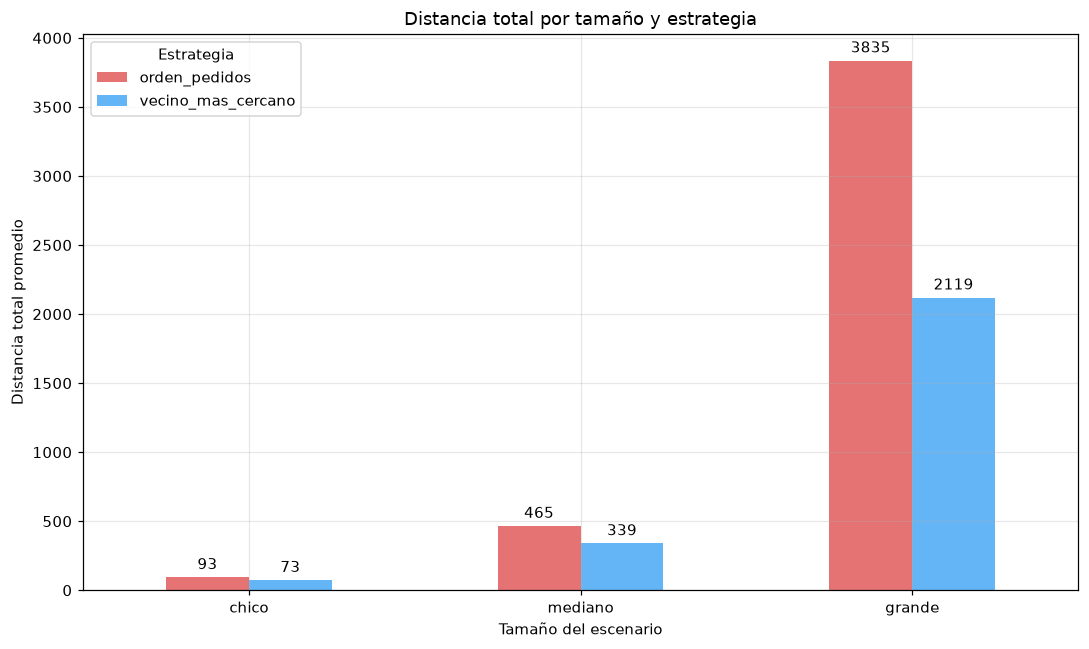

In [3]:
pivote = df_resumen.pivot_table(
    index="tamano",
    columns="estrategia_recorrido",
    values="dist_total",
    aggfunc="mean",
).loc[orden_tamano]

ax = pivote.plot(kind="bar", rot=0, color=["#e57373", "#64b5f6"])
ax.set_ylabel("Distancia total promedio")
ax.set_xlabel("Tamaño del escenario")
ax.set_title("Distancia total por tamaño y estrategia")
ax.legend(title="Estrategia")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(DIR / "grafico_distancias.png", dpi=120)
plt.show()

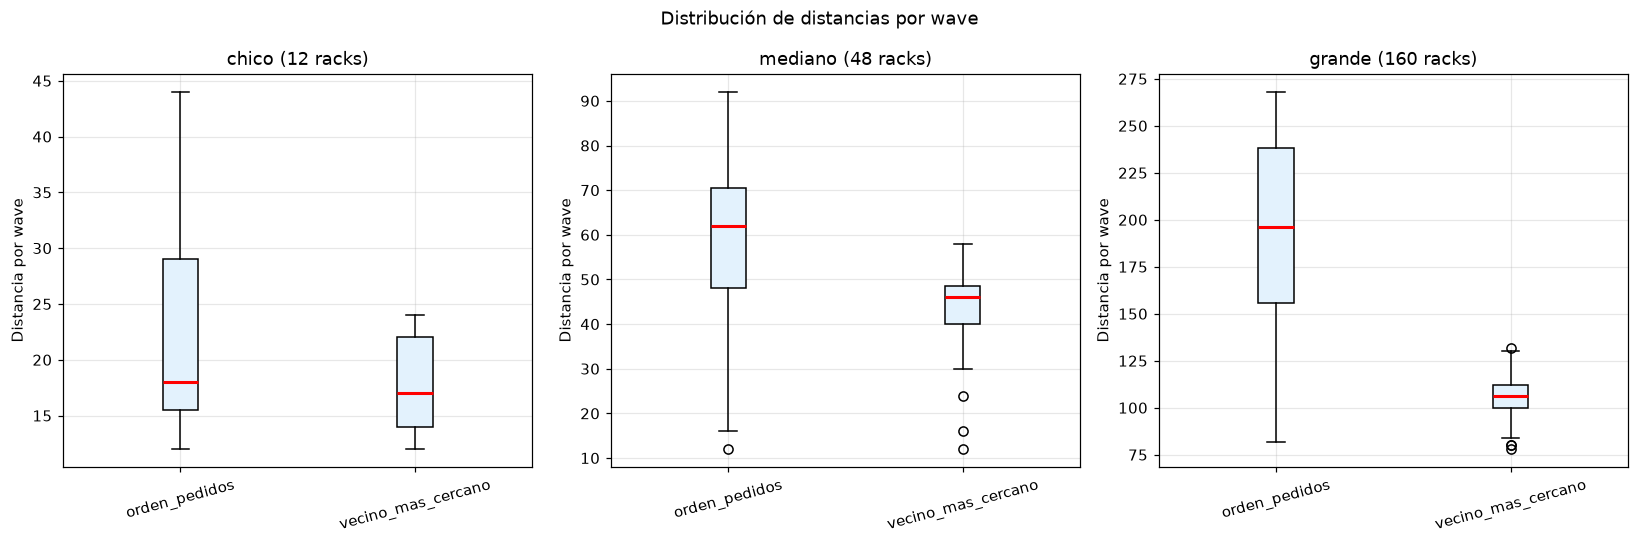

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, tam in zip(axes, orden_tamano):
    sub = df_waves[df_waves["tamano"] == tam]
    datos = [
        sub[sub["estrategia_recorrido"] == "orden_pedidos"]["distancia_total"],
        sub[sub["estrategia_recorrido"] == "vecino_mas_cercano"]["distancia_total"],
    ]
    ax.boxplot(
        datos,
        tick_labels=["orden_pedidos", "vecino_mas_cercano"],
        patch_artist=True,
        boxprops=dict(facecolor="#e3f2fd"),
        medianprops=dict(color="red", linewidth=2),
    )
    n_racks = sub["n_racks"].iloc[0]
    ax.set_title(f"{tam} ({n_racks} racks)")
    ax.set_ylabel("Distancia por wave")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Distribución de distancias por wave", fontsize=12)
plt.tight_layout()
plt.savefig(DIR / "grafico_boxplot.png", dpi=120)
plt.show()

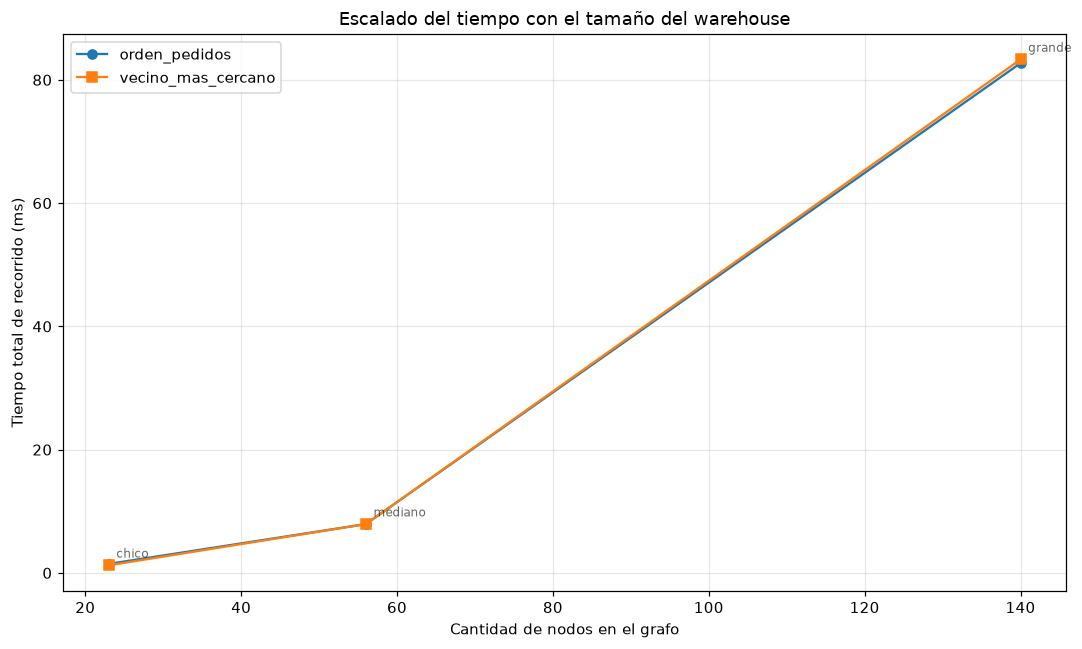

In [5]:
tiempos = df_resumen.pivot_table(
    index=["tamano", "n_nodos_grafo"],
    columns="estrategia_recorrido",
    values="t_recorrido_total_s",
    aggfunc="mean",
).reset_index()
tiempos = tiempos.sort_values("n_nodos_grafo")

fig, ax = plt.subplots()
ax.plot(tiempos["n_nodos_grafo"], tiempos["orden_pedidos"] * 1000,
        marker="o", label="orden_pedidos")
ax.plot(tiempos["n_nodos_grafo"], tiempos["vecino_mas_cercano"] * 1000,
        marker="s", label="vecino_mas_cercano")
ax.set_xlabel("Cantidad de nodos en el grafo")
ax.set_ylabel("Tiempo total de recorrido (ms)")
ax.set_title("Escalado del tiempo con el tamaño del warehouse")
ax.legend()

for _, fila in tiempos.iterrows():
    ax.annotate(
        fila["tamano"],
        (fila["n_nodos_grafo"], fila["vecino_mas_cercano"] * 1000),
        fontsize=8, alpha=0.6,
        xytext=(5, 5), textcoords="offset points",
    )

plt.tight_layout()
plt.savefig(DIR / "grafico_tiempos.png", dpi=120)
plt.show()

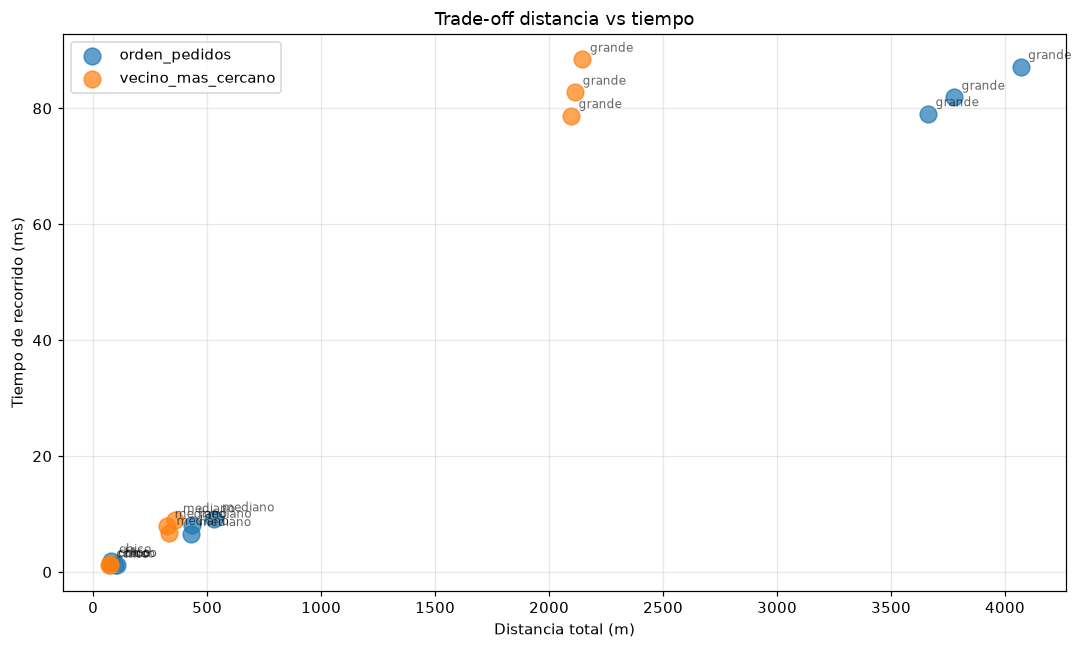

In [6]:
fig, ax = plt.subplots()

for estrat, grupo in df_resumen.groupby("estrategia_recorrido"):
    ax.scatter(
        grupo["dist_total"],
        grupo["t_recorrido_total_s"] * 1000,
        s=120, alpha=0.7, label=estrat,
    )
    for _, fila in grupo.iterrows():
        ax.annotate(
            fila["tamano"],
            (fila["dist_total"], fila["t_recorrido_total_s"] * 1000),
            fontsize=8, alpha=0.6,
            xytext=(5, 5), textcoords="offset points",
        )

ax.set_xlabel("Distancia total (m)")
ax.set_ylabel("Tiempo de recorrido (ms)")
ax.set_title("Trade-off distancia vs tiempo")
ax.legend()
plt.tight_layout()
plt.savefig(DIR / "grafico_tradeoff.png", dpi=120)
plt.show()

In [7]:
print("=" * 60)
print("RESPUESTAS A PARTIR DE LOS DATOS")
print("=" * 60)
print()

for tam in orden_tamano:
    sub = df_resumen[df_resumen["tamano"] == tam]
    op = sub[sub["estrategia_recorrido"] == "orden_pedidos"]["dist_total"].mean()
    vc = sub[sub["estrategia_recorrido"] == "vecino_mas_cercano"]["dist_total"].mean()
    print(f"{tam:>8s}: orden={op:>8.1f}  vecino={vc:>8.1f}  "
          f"mejora={(op - vc) / op * 100:>5.1f}%")

print()
print("¿Vecino más cercano gana siempre?")

tabla_estrategias = df_resumen.pivot_table(
    index="escenario",
    columns="estrategia_recorrido",
    values="dist_total",
)
victorias_vecino = (tabla_estrategias["vecino_mas_cercano"] < tabla_estrategias["orden_pedidos"]).sum()
print(f"  Victorias de vecino_mas_cercano: {victorias_vecino}/{len(tabla_estrategias)}")

RESPUESTAS A PARTIR DE LOS DATOS

   chico: orden=    93.3  vecino=    72.7  mejora= 22.1%
 mediano: orden=   464.7  vecino=   338.7  mejora= 27.1%
  grande: orden=  3835.3  vecino=  2118.7  mejora= 44.8%

¿Vecino más cercano gana siempre?
  Victorias de vecino_mas_cercano: 9/9
